# Load libraries

In [ ]:
import numpy as np
import itertools, pandas as pd
from models import LinearModel, ChoquetModel, LipschitzModel
from tests import (
    ZDT1, ZDT2, ZDT3, DTLZ1, DTLZ2,
    ZDT1_Shifted, ZDT2_Shifted, ZDT2_Combined,
    Kursawe, Fon, Sch1, Sch2,
    Ackley01, Schwefel04, Gulf,
    ExtendedProblem
)

import matplotlib.pyplot as plt
from utils import evaluate, visualise_weights

# Modelling

In [2]:
# ZDT calling
# linear_model = LinearModel(problem = ZDT1(n_dim = 5), max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = ZDT1(n_dim = 5), max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = ZDT1(n_dim = 5), max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2) # ZDT3 is bi-objective

# # DTLZ calling
# linear_model = LinearModel(problem = DTLZ1(n_dim = 10, n_obj = 5), max_iter = 5, random_state = 42)
# choquet_model = ChoquetModel(problem = DTLZ1(n_dim = 10, n_obj = 5), max_iter = 5, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = DTLZ1(n_dim = 10, n_obj = 5), max_iter = 5, random_state = 42,
#                             type = "global_mon", num_k = 2)

In [3]:
# Self-constructed calling
# linear_model = LinearModel(problem = ZDT1_Shifted(n_dim = 5), max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = ZDT1_Shifted(n_dim = 5), max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = ZDT1_Shifted(n_dim = 5), max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

# linear_model = LinearModel(problem = ZDT2_Combined(n_dim = 10, order = [0, 1], C = 0.2), max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = ZDT2_Combined(n_dim = 10, order = [0, 1], C = 0.2), max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = ZDT2_Combined(n_dim = 10, order = [0, 1], C = 0.2), max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

In [4]:
extended_problem = ExtendedProblem(
    problems = [Schwefel04(n_dim = 10), Gulf()],
    order = None
)

In [5]:
# linear_model = LinearModel(problem = Sch1(n_dim = 5), max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = Sch1(n_dim = 5), max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = Sch1(n_dim = 5), max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

linear_model = LinearModel(problem = extended_problem, max_iter = 10, random_state = 42)
choquet_model = ChoquetModel(problem = extended_problem, max_iter = 10, random_state = 42, method = 2)
slip_model = LipschitzModel(problem = extended_problem, max_iter = 10, random_state = 42,
                            type = "global_mon", num_k = 2)

In [6]:
# Let them solve
linear_model.solve()
choquet_model.solve()
slip_model.solve()

# Summary their performance metrics

print(f"LinearModel :  PF {linear_model.PF.shape}  PS {linear_model.PS.shape}")
print(f"ChoquetModel:  PF {choquet_model.PF.shape} PS {choquet_model.PS.shape}")
print(f"LipschitzModel:  PF {slip_model.PF.shape} PS {slip_model.PS.shape}")
evaluate([linear_model, choquet_model, slip_model])

/Users/admin/Deakin/Year_3/T2:2026/SIT316 - Linear And Nonlinear Optimisation/Portfolio/HD Project/src/pymoo_tests.py:264: RuntimeWarning: divide by zero encountered in divide
  return np.sum((np.exp(-np.abs(self.u - z[1]) ** z[2] / z[0]) - self.t) ** 2)


LinearModel :  PF (170, 2)  PS (170, 10)
ChoquetModel:  PF (67, 2) PS (67, 10)
LipschitzModel:  PF (70, 2) PS (70, 10)


,hypervolume,n_func_eval,n_non_dominated,n_iter,wallclock_time
LinearModel,913970.319864,53674,170,10,16.786394
ChoquetModel,912821.608691,37832,67,10,10.475458
LipschitzModel,912572.063189,15650,70,10,10.278064


# Model visualisation

In [7]:
# for kind in ["symmetric", "absolute", "norm"]:
#     visualise_weights(choquet_model, kind = kind);

In [8]:
# linear_model.visualise("true_pf");

## Linear Model

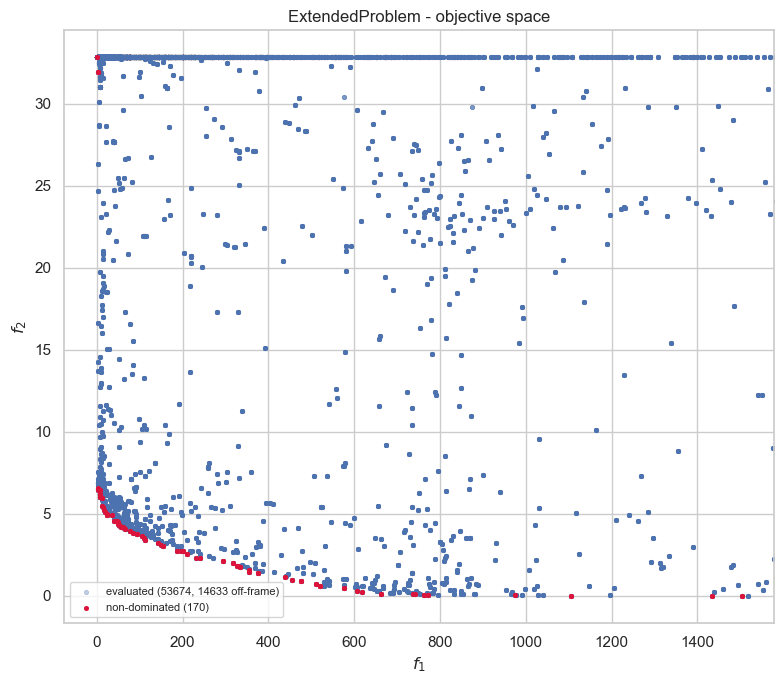

In [9]:
linear_model.visualise("objective");

In [10]:
linear_model.visualise("learning", show = False)

In [11]:
linear_model.visualise("learning", plot_scalarisation = True, show = False)

## Choquet Model

In [12]:
np.all((choquet_model.dec_hist >= 0) & (choquet_model.dec_hist <= 1))

np.True_

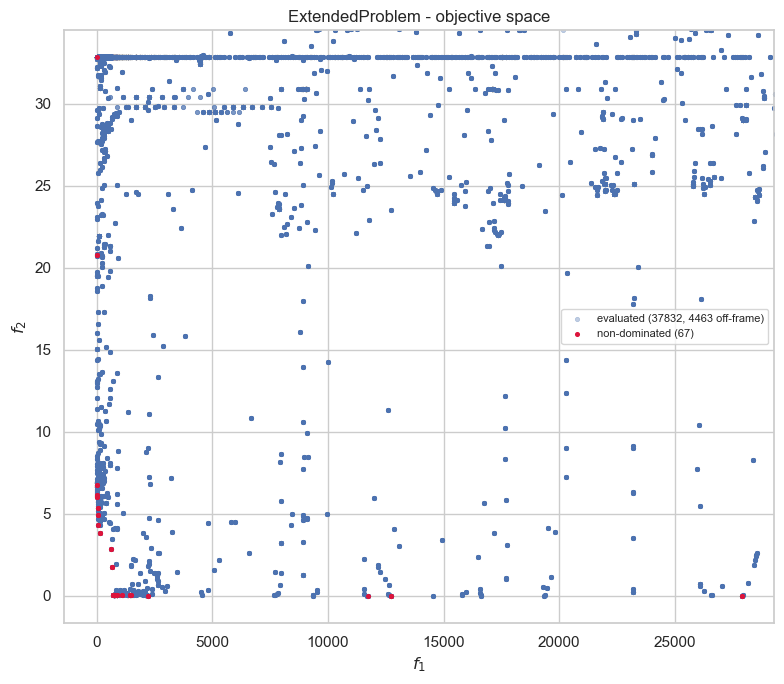

In [13]:
choquet_model.visualise("objective");

In [14]:
choquet_model.visualise("learning", show = False)

In [15]:
choquet_model.visualise("learning", plot_scalarisation = True, show = False)

## Lipschitz Model

In [16]:
np.all((slip_model.dec_hist >= 0) & (slip_model.dec_hist <= 1))

np.True_

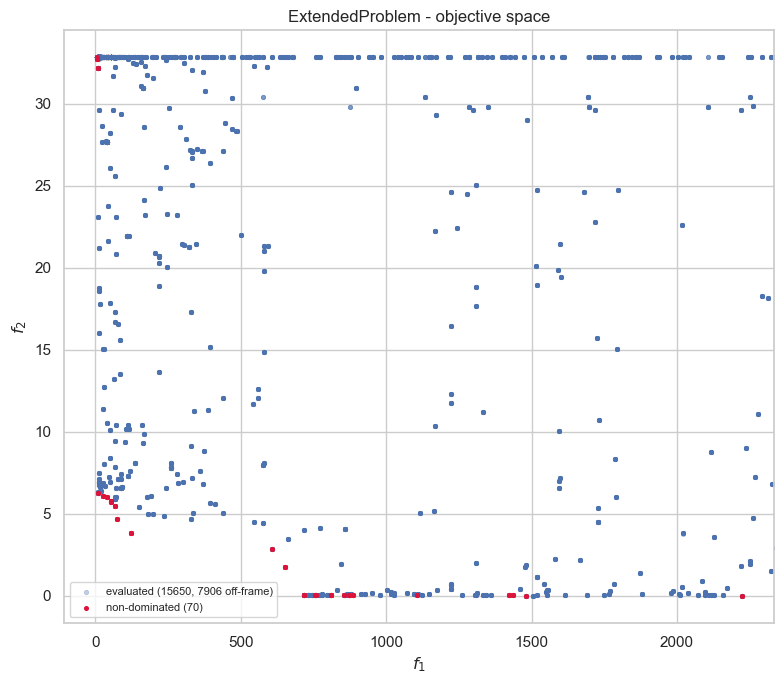

In [17]:
slip_model.visualise("objective");

In [18]:
slip_model.visualise("learning", show = False)

In [19]:
slip_model.visualise("learning", plot_scalarisation = True, show = False)

# Pareto Front and Pareto Set statistics

This section displays the statistics of the Pareto front and Pareto set found by the above-mentioned models. Note that, these are the set of non-dominated solutions, not all the iterates obtained throughout their runs.

In [20]:
import seaborn as sns


def plot_distributions(arrays, symbol, title):
    """Box plot and per-component ECDFs of each model's points; arrays maps model name -> (n_points, n_components)."""
    long = pd.concat(
        [pd.DataFrame(a).rename(columns = lambda k: f"${symbol}_{{{k + 1}}}$")
           .melt(var_name = "component", value_name = "value")
           .assign(model = f"{name} (n={len(a)})")
         for name, a in arrays.items()],
        ignore_index = True,
    )
    n_comp = long["component"].nunique()

    fig, ax = plt.subplots(figsize = (max(6, 1.6 * n_comp), 4))
    sns.boxplot(data = long, x = "component", y = "value", hue = "model", ax = ax,
                fliersize = 2, linewidth = 0.8)
    ax.set(xlabel = None, ylabel = f"${symbol}$", title = f"{title}: distribution per component")
    sns.move_legend(ax, "upper left", bbox_to_anchor = (1, 1), frameon = False)
    plt.show()

    g = sns.displot(long, x = "value", hue = "model", col = "component", kind = "ecdf",
                    col_wrap = min(n_comp, 5), height = 2.8, aspect = 1)
    g.set_titles("{col_name}")
    g.set_axis_labels(f"${symbol}$", "ECDF")
    g.figure.suptitle(f"{title}: empirical CDF per component", y = 1.04)
    plt.show()

## Pareto Front

In [21]:
# arr = {
#     "baseline": linear_model.PF,
#     "cas": choquet_model.PF,
#     "las": slip_model.PF
# }

arr = {
    "baseline": linear_model.obj_hist,
    "cas": choquet_model.obj_hist,
    "las": slip_model.obj_hist
}

df = pd.concat({name: pd.DataFrame(a) for name, a in arr.items()}, axis = 1)
df.columns.names = ["model", "k"]
df.describe()

model      baseline                         cas                         las  \
k                 0             1             0             1             0   
count  53674.000000  53674.000000  37832.000000  37832.000000  15650.000000   
mean    3776.738629     27.486385   7237.489073     28.660716   7758.228733   
std     8300.238588     10.504602  11100.846103      9.501097  10790.319521   
min        0.017971      0.011950      0.395229      0.000117      4.764156   
25%       11.642534     29.505977     55.954885     29.829735    299.582380   
50%      165.364884     32.835000    505.014828     32.835000   2409.882210   
75%     2085.256409     32.835000  12383.578431     32.835000  12003.606263   
max    73730.000000     39.550303  81810.000000     39.550303  81810.000000   

model                
k                 1  
count  15650.000000  
mean      26.159810  
std       11.592715  
min        0.004527  
25%       23.247679  
50%       32.835000  
75%       32.835000  
max       39.550303

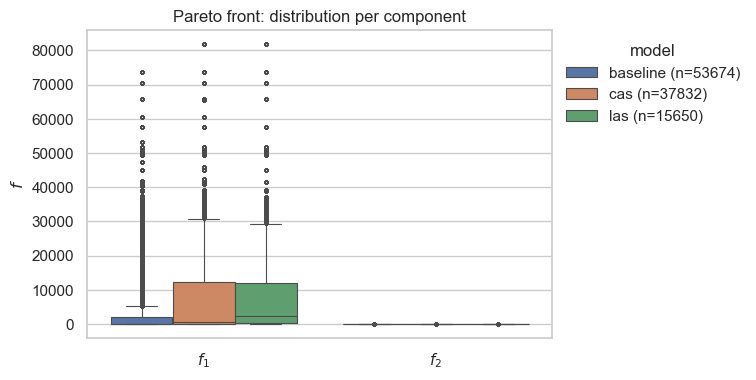

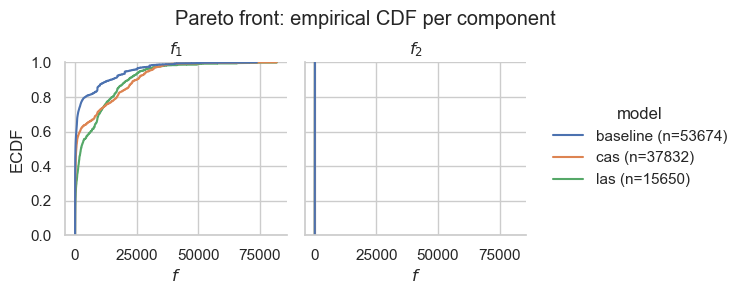

In [22]:
plot_distributions(arr, "f", "Pareto front")

## Pareto Set

In [23]:
# arr = {
#     "baseline": linear_model.PS,
#     "cas": choquet_model.PS,
#     "las": slip_model.PS
# }

arr = {
    "baseline": linear_model.dec_hist,
    "cas": choquet_model.dec_hist,
    "las": slip_model.dec_hist
}

df = pd.concat({name: pd.DataFrame(a) for name, a in arr.items()}, axis = 1)
df.columns.names = ["model", "k"]
df.describe()

model      baseline                                                          \
k                 0             1             2             3             4   
count  53674.000000  53674.000000  53674.000000  53674.000000  53674.000000   
mean       0.299169      0.253833      0.184103      0.185303      0.188277   
std        0.254262      0.254686      0.204822      0.201995      0.202700   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.122448      0.071933      0.021324      0.058018      0.060605   
50%        0.222471      0.157632      0.129630      0.129630      0.131360   
75%        0.401360      0.386918      0.253958      0.230911      0.235279   
max        1.000000      1.000000      1.000000      1.000000      1.000000   

model                                                                        \
k                 5             6             7             8             9   
count  53674.000000  53674.000000  53674.000000  53674.000000  53674.000000   
mean       0.193682      0.189765      0.195023      0.192233      0.190138   
std        0.204120      0.198107      0.205003      0.199042      0.201791   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.061509      0.064831      0.069189      0.066316      0.059752   
50%        0.137032      0.134657      0.134292      0.132559      0.130678   
75%        0.247985      0.241227      0.245177      0.247699      0.247841   
max        1.000000      1.000000      1.000000      1.000000      1.000000   

model  ...           las                                            \
k      ...             0             1             2             3   
count  ...  15650.000000  15650.000000  15650.000000  15650.000000   
mean   ...      0.398841      0.366312      0.259702      0.267607   
std    ...      0.301712      0.306934      0.286482      0.262725   
min    ...      0.000000      0.000000      0.000000      0.000000   
25%    ...      0.143909      0.104816      0.020815      0.069982   
50%    ...      0.359933      0.316036      0.166667      0.170727   
75%    ...      0.614219      0.550909      0.438238      0.384504   
max    ...      1.000000      1.000000      1.000000      1.000000   

model                                                                        \
k                 4             5             6             7             8   
count  15650.000000  15650.000000  15650.000000  15650.000000  15650.000000   
mean       0.276304      0.293839      0.290000      0.292151      0.292870   
std        0.261971      0.274586      0.264678      0.260125      0.259562   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.069984      0.057850      0.065171      0.087650      0.096391   
50%        0.176773      0.206267      0.227500      0.209103      0.207418   
75%        0.398581      0.469452      0.434760      0.453192      0.451156   
max        1.000000      1.000000      1.000000      1.000000      1.000000   

model                
k                 9  
count  15650.000000  
mean       0.301011  
std        0.274030  
min        0.000000  
25%        0.057027  
50%        0.234727  
75%        0.475561  
max        1.000000  

[8 rows x 30 columns]

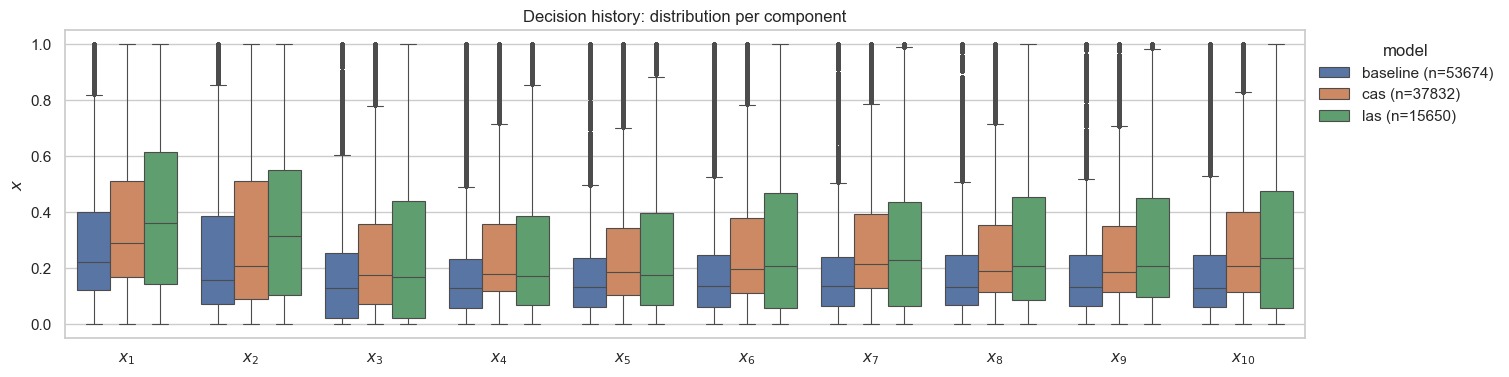

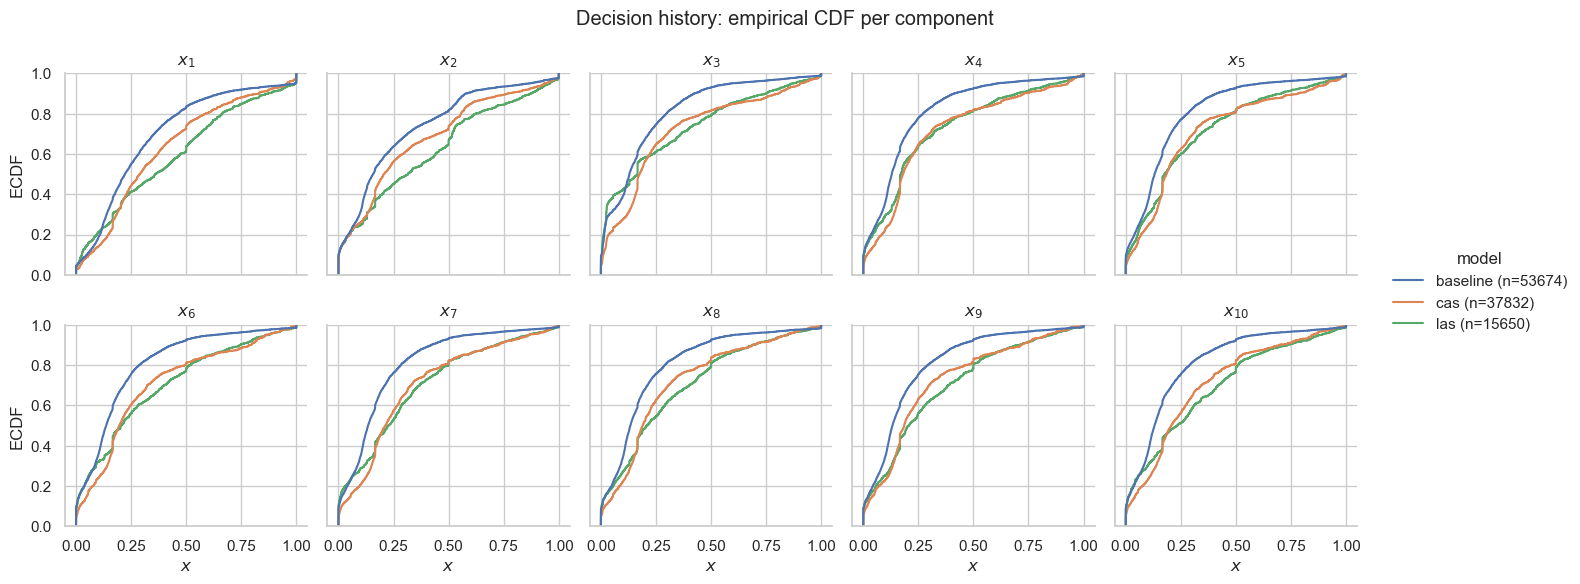

In [24]:
plot_distributions(arr, "x", "Decision history")

# Benchmark

Every configuration is solved by both models from the same seed, then scored by `evaluate()` against one shared reference point.

- **ZDT1/2/3** are 2-objective by construction, so they appear once per `n_dim` and ignore `obj_dims`.
- **DTLZ1/2** take `n_obj`, and are skipped when `n_dim <= n_obj` - there would be no tail variables left to carry `g`.
- Hypervolume is comparable **within** a row group only; the reference point differs between configurations, so never compare it across problems or dimensions.

In [25]:
# dec_dims   = [10, 20]
# obj_dims   = [2, 3, 4, 5]
# max_iter   = 50
# model_list = [LinearModel, ChoquetModel, LipschitzModel]
# prob_list  = [ZDT1, ZDT2, ZDT3, DTLZ1, DTLZ2]


# def build(problem, n_dim, n_obj):
#     """This grid cell's problem, or None if the combination does not exist: ZDT is 2-objective by
#        construction, and DTLZ needs n_dim > n_obj to leave tail variables to carry g."""
#     if problem in (ZDT1, ZDT2, ZDT3):
#         return problem(n_dim = n_dim) if n_obj == 2 else None
#     return problem(n_dim = n_dim, n_obj = n_obj) if n_dim > n_obj else None


# rows = []
# for problem, n_dim, n_obj in itertools.product(prob_list, dec_dims, obj_dims):
#     prob = build(problem, n_dim, n_obj)
#     if prob is None:
#         continue

#     fitted = [model(problem = prob, max_iter = max_iter, random_state = 42,
#                     **(dict(method = 2) if model is ChoquetModel else {}))
#               for model in model_list]
#     for m in fitted:
#         m.solve()

#     # evaluate() scores the pair against one shared reference point, and already times each solve
#     rows.append(evaluate(fitted).assign(problem = problem.__name__, n_dim = n_dim,
#                                         n_obj = prob.n_obj))
#     print(problem.__name__, f"n_dim={n_dim}", f"n_obj={prob.n_obj}",
#           dict(rows[-1]["wallclock_time"].round(1)))

# results = (pd.concat(rows).rename_axis("model").reset_index()
#              .set_index(["problem", "n_dim", "n_obj", "model"]).sort_index())
# results

In [26]:
# # hypervolume only compares within a configuration, so pick a winner per row
# hv = results["hypervolume"].unstack("model")
# hv.assign(winner = hv.idxmax(1), gap_pct = 100 * (hv.max(1) - hv.min(1)) / hv.max(1)).round(4)